<a href="https://colab.research.google.com/github/mehmethanbubekoglu1-dev/ARASTIRMA-YONTEM-VE-TEKNIKLERI/blob/main/Hafta6_AI_ve_Ders_Calisma_Analizi%20(6).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6. Hafta | Kendi Projemin Veri Analizi — Ekip Teslim Şablonu

**Hazırlayan:** Mehmethan Bubekoğlu (361526034) • **Proje:** Yapay zekâ kullanım sıklığı ile haftalık bağımsız ders çalışma süresi arasındaki ilişki • **Ekip görevleri:** Veri hazırlama (CSV/JSON), hesaplama, grafikler, yorum, README ve GitHub yüklemesi (ayrıntı: bölüm G ve README.md)

Bu notebook, 6. hafta ekip teslim şablonunun ve Colab uygulamasının (CSV/JSON okuma, grafik, sonuç dosyaları, ekip çalışması) proje konumuza uyarlanmış hâlidir.

> ✅ **Bu notebook'ta gerçek, açık lisanslı (CC BY 4.0) bir anket veri seti kullanılır** (Mendeley Data, DOI: 10.17632/mcwb2ppdsw.1). Veri bizim tarafımızdan üretilmemiştir; kaynak ve lisans bölüm A'da belirtilmiştir.

## 0. Veri gizliliği, güvenlik ve lisans kurallarına uyum
Ders kurallarına (HAFTA6_DERSTE KULLANILAN KAYNAKLAR) göre bu çalışmada:
1. **Kişisel ve gizli bilgi yoktur:** Şifre, API anahtarı, erişim token'ı veya kimlik doğrulama bilgisi notebook'ta/repoda bulunmaz.
2. **Veri seti lisansı kontrol edildi:** Veri seti **CC BY 4.0** lisanslıdır; kaynak gösterilerek kullanılabilir, paylaşılabilir ve yeniden dağıtılabilir.
3. **Kişisel veri:** Veri setinde ad, soyad, telefon, e-posta, kimlik/öğrenci numarası, adres bulunmaz; yanıt zaman damgası veri sahibi tarafından kaldırılmıştır (`response_date` boştur). Analizde yalnızca **iki değişken** kullanılır; yaş, cinsiyet ve program gibi sütunlar analiz çıktılarına alınmaz.
4. **Kaynak gösterimi:** Veri adı, yazar, kaynak, bağlantı, DOI ve lisans bölüm A'dadır.
5. **GitHub ve Colab güvenliği:** Paylaşmadan önce kod, veri dosyaları ve çıktı hücreleri kontrol edilmiştir; çıktılarda gizli bilgi yoktur.

## A. Veri tanıtımı
- **Veri setinin adı ve bağlantısı:** *Study habits and artificial intelligence use among university students: A proportionally stratified survey dataset* — https://data.mendeley.com/datasets/mcwb2ppdsw/1
- **Veri kaynağı / lisans / erişim tarihi:** Mendeley Data (Sürüm 1, 18 Mart 2026), yazar: Cristian David Correa Álvarez (Universidad Nacional de Colombia) • DOI: 10.17632/mcwb2ppdsw.1 • **Lisans: CC BY 4.0** • Erişim tarihi: 08.11.2026
- **Önerilen atıf:** Correa Álvarez, C. D. (2026). *Study habits and artificial intelligence use among university students: A proportionally stratified survey dataset* (Sürüm 1) [Veri seti]. Mendeley Data. https://doi.org/10.17632/mcwb2ppdsw.1 (veri sahibi ayrıca ilgili Data Descriptor makalesine atıf yapılmasını ister)
- **CSV mi, JSON mu?** Kaynak dosya CSV'dir (`survey_cleaned_english.csv`); kullandığımız iki sütun ayrıca JSON olarak da kaydedilip okunmuştur
- **Satır ve sütunların anlamı:** Her satır bir anket yanıtıdır (kişi). Kaynak dosya 357 satır × 31 sütundur; bu çalışmada yalnızca şu iki sütun kullanılır:
  - `independent_study_time` (anket sorusu Q9): *"Haftada ortalama kaç saat bağımsız ders çalışıyorsunuz?"* — aralık cevabı: 0-1, 1-2, 2-3, 3-4, 4-5, 5'ten fazla (saat/hafta)
  - `ai_use_frequency_for_study` (Q20): *"Derslerinizde yapay zekâ araçlarını ne sıklıkla kullanıyorsunuz?"* — Hiç (Never), Nadiren (Rarely), Ara sıra (Occasionally), Çoğunlukla (Almost always), Her zaman (Always)
- **Ölçü birimi ve gözlem sayısı:** Çalışma süresi saat/hafta (aralıklı); yapay zekâ kullanımı sıralı (ordinal) sıklık ölçeği • 357 gözlem
- **Gerçek mi / açık kaynak mı / temsili mi?** **Gerçek ve açık kaynak** (Kolombiya'da bir devlet üniversitesinin Manizales yerleşkesinde 14 programdan 357 lisans öğrencisiyle yapılan, 2025 güz dönemi, orantılı tabakalı/kota örneklemli anket; öz-bildirimli ve tek yerleşke)
- **Ekip üyelerinin görevleri:** Mehmethan Bubekoğlu (361526034): Veri hazırlama (CSV/JSON), hesaplama, grafikler, yorum, README ve GitHub yüklemesi (bölüm G)

## B. Başlangıç: gerçek veriyi okuma
`survey_cleaned_english.csv` dosyası (Mendeley Data'dan indirilen, bu notebook'la aynı klasöre konmuş orijinal dosya) okunur. Colab'da **Dosyalar → Yükle** ile aynı klasöre yükleyin. Analiz için gereken iki sütun seçilir ve CSV + JSON olarak kaydedilip yeniden okunur.

In [ ]:
from pathlib import Path
import pandas as pd

veri_yolu = "survey_cleaned_english.csv"  # Mendeley Data (CC BY 4.0) orijinal dosyası
if not Path(veri_yolu).exists():
    raise FileNotFoundError(f"{veri_yolu} bulunamadı. Dosyayı Mendeley Data sayfasından indirip bu klasöre koyun.")

tam_veri = pd.read_csv(veri_yolu)
print("Kaynak dosya boyutu (satır, sütun):", tam_veri.shape)

# Yalnızca analiz için gereken iki sütunu al (gizlilik: gereksiz sütunlar çıktıya alınmaz)
veri = tam_veri[["independent_study_time", "ai_use_frequency_for_study"]].copy()
veri.to_csv("kullanilan_veri.csv", index=False, encoding="utf-8-sig")
veri.to_json("kullanilan_veri.json", orient="records", force_ascii=False, indent=2)

csv_tablo = pd.read_csv("kullanilan_veri.csv")
json_tablo = pd.read_json("kullanilan_veri.json")
print("CSV ve JSON aynı satır sayısına sahip mi?", len(csv_tablo) == len(json_tablo))
print(csv_tablo.head())

Kaynak dosya boyutu (satır, sütun): (357, 31)
CSV ve JSON aynı satır sayısına sahip mi? True
  independent_study_time ai_use_frequency_for_study
0                    3-4              Almost always
1            More than 5              Almost always
2                    3-4                     Always
3            More than 5              Almost always
4                    4-5              Almost always


## C. Veri inceleme ve hesaplama
Her iki değişken de **sıralı (ordinal)** kategorilerdir; bu yüzden korelasyon için **Spearman sıra korelasyonu (ρ)** kullanılır. Çalışma süresi aralık olarak verildiği için ortalama süre **tahminidir**: aralıkların orta noktası alınır, "5'ten fazla" için en düşük değer olan 5 saat kullanılır; dolayısıyla ortalama **alt sınır tahminidir** (gerçek ortalama daha yüksektir). Birimler: çalışma süresi saat/hafta.

In [ ]:
from scipy.stats import spearmanr

print("Sütunlar:", list(veri.columns))
print("Eksik kayıt sayıları:\n", veri.isna().sum())
print()

sure_kodu = {"0-1": 1, "1-2": 2, "2-3": 3, "3-4": 4, "4-5": 5, "More than 5": 6}
sure_orta = {"0-1": 0.5, "1-2": 1.5, "2-3": 2.5, "3-4": 3.5, "4-5": 4.5, "More than 5": 5.0}  # son değer alt sınır
sik_kodu = {"Never": 1, "Rarely": 2, "Occasionally": 3, "Almost always": 4, "Always": 5}
sik_tr = {"Never": "Hiç", "Rarely": "Nadiren", "Occasionally": "Ara sıra", "Almost always": "Çoğunlukla", "Always": "Her zaman"}

veri["sure_kodu"] = veri["independent_study_time"].map(sure_kodu)
veri["sure_saat_tahmini"] = veri["independent_study_time"].map(sure_orta)
veri["sik_kodu"] = veri["ai_use_frequency_for_study"].map(sik_kodu)

N = len(veri)
print("Gözlem sayısı (toplam):", N)
print("Çalışma süresi dağılımı (kişi):")
print(veri["independent_study_time"].value_counts().reindex(list(sure_kodu)).to_string())
print()
print("Yapay zekâ kullanım sıklığı dağılımı (kişi):")
print(veri["ai_use_frequency_for_study"].value_counts().reindex(list(sik_kodu)).to_string())
print()

toplam_saat = veri["sure_saat_tahmini"].sum()
ort_saat = veri["sure_saat_tahmini"].mean()
medyan_kat = veri["independent_study_time"].iloc[(veri["sure_kodu"]).sort_values().index[N // 2]]
yuzde_5ustu = (veri["independent_study_time"] == "More than 5").mean() * 100
yuzde_yuksek_ai = veri["ai_use_frequency_for_study"].isin(["Almost always", "Always"]).mean() * 100
print(f"Toplam haftalık çalışma (alt sınır tahmini): {toplam_saat:.0f} saat/hafta (357 kişi toplamı)")
print(f"Ortalama haftalık çalışma (alt sınır tahmini): {ort_saat:.2f} saat/hafta")
print(f"Medyan çalışma kategorisi: {medyan_kat}")
print(f"'5 saatten fazla' diyenlerin oranı: %{yuzde_5ustu:.1f}")
print(f"Yapay zekâyı 'çoğunlukla/her zaman' kullananların oranı: %{yuzde_yuksek_ai:.1f}")

rho, p = spearmanr(veri["sik_kodu"], veri["sure_kodu"])
print(f"\nSpearman ρ = {rho:.3f} (p = {p:.3f}, n = {N})")

# Yapay zekâ kullanım gruplarına göre özet (Hiç ve Nadiren az kişi içerdiği için birleştirildi)
grup_haritasi = {"Never": "Hiç/Nadiren", "Rarely": "Hiç/Nadiren", "Occasionally": "Ara sıra",
                 "Almost always": "Çoğunlukla", "Always": "Her zaman"}
grup_sirasi = ["Hiç/Nadiren", "Ara sıra", "Çoğunlukla", "Her zaman"]
veri["ai_grubu"] = pd.Categorical(veri["ai_use_frequency_for_study"].map(grup_haritasi),
                                  categories=grup_sirasi, ordered=True)
grup_ozet = veri.groupby("ai_grubu", observed=True).agg(
    kisi=("sure_saat_tahmini", "size"),
    ort_saat=("sure_saat_tahmini", "mean"),
    yuzde_5ustu=("independent_study_time", lambda s: (s == "More than 5").mean() * 100)).round(2)
print()
print(grup_ozet)

Sütunlar: ['independent_study_time', 'ai_use_frequency_for_study']
Eksik kayıt sayıları:
 independent_study_time        0
ai_use_frequency_for_study    0
dtype: int64

Gözlem sayısı (toplam): 357
Çalışma süresi dağılımı (kişi):
independent_study_time
0-1              7
1-2             21
2-3             34
3-4             52
4-5             60
More than 5    183

Yapay zekâ kullanım sıklığı dağılımı (kişi):
ai_use_frequency_for_study
Never              2
Rarely            28
Occasionally     109
Almost always    159
Always            59

Toplam haftalık çalışma (alt sınır tahmini): 1487 saat/hafta (357 kişi toplamı)
Ortalama haftalık çalışma (alt sınır tahmini): 4.17 saat/hafta
Medyan çalışma kategorisi: More than 5
'5 saatten fazla' diyenlerin oranı: %51.3
Yapay zekâyı 'çoğunlukla/her zaman' kullananların oranı: %61.1

Spearman ρ = 0.038 (p = 0.473, n = 357)

             kisi  ort_saat  yuzde_5ustu
ai_grubu                                
Hiç/Nadiren    30      4.03        53.33
Ara 

## D. Grafik ve sonuç dosyaları
- **Grafik 1:** Yapay zekâ kullanım grubuna göre çalışma süresi dağılımı (yüzde, 100% yığılmış sütun).
- **Grafik 2:** Gruplara göre ortalama haftalık çalışma süresi (alt sınır tahmini).
- Grafikler betimleyicidir; tek başına neden-sonuç ilişkisi kanıtlamaz. Birimler eksenlerde belirtilmiştir.

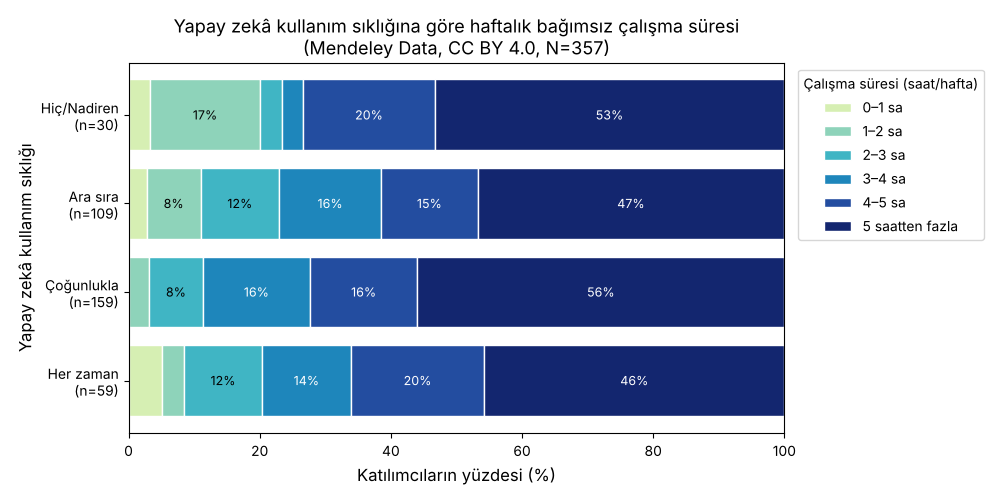

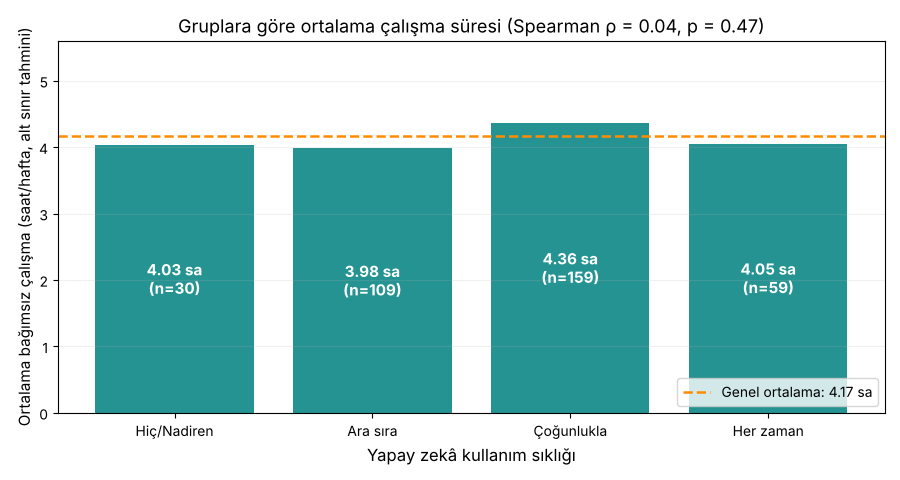

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

klasor = Path("sonuc")
klasor.mkdir(exist_ok=True)

# --- Grafik 1: dağılım (100% yığılmış yatay çubuk) ---
sure_etiket = ["0–1 sa", "1–2 sa", "2–3 sa", "3–4 sa", "4–5 sa", "5 saatten fazla"]
tablo = (pd.crosstab(veri["ai_grubu"], veri["independent_study_time"], normalize="index")
         .reindex(columns=list(sure_kodu)).fillna(0) * 100)
renkler = plt.cm.YlGnBu(np.linspace(0.2, 0.95, 6))

fig, ax = plt.subplots(figsize=(10, 5))
sol = np.zeros(len(tablo))
for i, kol in enumerate(tablo.columns):
    ax.barh(range(len(tablo)), tablo[kol], left=sol, color=renkler[i], label=sure_etiket[i], edgecolor="white")
    for j, v in enumerate(tablo[kol]):
        if v >= 6:
            ax.text(sol[j] + v / 2, j, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if i >= 3 else "black")
    sol += tablo[kol].values
ax.set_yticks(range(len(tablo)))
ax.set_yticklabels([f"{g}\n(n={int(grup_ozet.loc[g, 'kisi'])})" for g in tablo.index])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Katılımcıların yüzdesi (%)", fontsize=12)
ax.set_ylabel("Yapay zekâ kullanım sıklığı", fontsize=12)
ax.set_title("Yapay zekâ kullanım sıklığına göre haftalık bağımsız çalışma süresi\n(Mendeley Data, CC BY 4.0, N=357)", fontsize=13)
ax.legend(title="Çalışma süresi (saat/hafta)", bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
fig.savefig(klasor / "grafik_dagilim.png", dpi=160)
plt.show()

# --- Grafik 2: grup ortalamaları ---
fig2, ax2 = plt.subplots(figsize=(9, 4.8))
cubuk = ax2.bar(grup_ozet.index.astype(str), grup_ozet["ort_saat"], color="teal", alpha=0.85)
for c, (k, m) in zip(cubuk, zip(grup_ozet["kisi"], grup_ozet["ort_saat"])):
    ax2.text(c.get_x() + c.get_width() / 2, m / 2, f"{m:.2f} sa\n(n={int(k)})", ha="center", va="center", fontsize=11, color="white", fontweight="bold")
ax2.axhline(ort_saat, color="darkorange", ls="--", lw=1.8, label=f"Genel ortalama: {ort_saat:.2f} sa")
ax2.set_ylim(0, 5.6)
ax2.set_xlabel("Yapay zekâ kullanım sıklığı", fontsize=12)
ax2.set_ylabel("Ortalama bağımsız çalışma (saat/hafta, alt sınır tahmini)", fontsize=11)
ax2.set_title(f"Gruplara göre ortalama çalışma süresi (Spearman ρ = {rho:.2f}, p = {p:.2f})", fontsize=13)
ax2.grid(axis="y", alpha=.18); ax2.legend(loc="lower right")
fig2.tight_layout()
fig2.savefig(klasor / "grafik_ortalama.png", dpi=160)
plt.show()

### Sonuçları CSV, JSON, PNG ve ZIP olarak saklama
Not defterini kaydetmek, çalışma ortamının geçici dosyalarını otomatik saklamaz; bu yüzden sonuçlar `sonuc` klasörüne yazılır ve ZIP'lenir.

In [ ]:
import shutil

veri[["independent_study_time", "ai_use_frequency_for_study"]].to_csv(
    klasor / "kullanilan_veri.csv", index=False, encoding="utf-8-sig")
veri[["independent_study_time", "ai_use_frequency_for_study"]].to_json(
    klasor / "kullanilan_veri.json", orient="records", force_ascii=False, indent=2)

ozet = pd.DataFrame([
    {"metrik": "Gözlem sayısı", "deger": N, "birim": "kişi"},
    {"metrik": "Toplam haftalık çalışma (alt sınır tahmini)", "deger": round(toplam_saat), "birim": "saat/hafta"},
    {"metrik": "Ortalama haftalık çalışma (alt sınır tahmini)", "deger": round(ort_saat, 2), "birim": "saat/hafta"},
    {"metrik": "5 saatten fazla çalışanların oranı", "deger": round(yuzde_5ustu, 1), "birim": "%"},
    {"metrik": "Yapay zekâyı çoğunlukla/her zaman kullananların oranı", "deger": round(yuzde_yuksek_ai, 1), "birim": "%"},
    {"metrik": "Spearman rho", "deger": round(rho, 3), "birim": "birimsiz"},
    {"metrik": "Spearman p-değeri", "deger": round(p, 3), "birim": "birimsiz"},
])
ozet.to_csv(klasor / "ozet.csv", index=False, encoding="utf-8-sig")
ozet.to_json(klasor / "ozet.json", orient="records", indent=2, force_ascii=False)
grup_ozet.to_csv(klasor / "grup_ozet.csv", encoding="utf-8-sig")
print("Oluşan dosyalar:", sorted(p_.name for p_ in klasor.iterdir()))

zip_yolu = shutil.make_archive("ai_calisma_sonuclar", "zip", "sonuc")
print("İndirilebilir ZIP:", Path(zip_yolu).name)

Oluşan dosyalar: ['grafik_dagilim.png', 'grafik_ortalama.png', 'grup_ozet.csv', 'kullanilan_veri.csv', 'kullanilan_veri.json', 'ozet.csv', 'ozet.json']
İndirilebilir ZIP: ai_calisma_sonuclar.zip


## E. Akademik yorum
**Veri kaynağı ve değişken:** Mendeley Data'daki (CC BY 4.0) gerçek anket veri setinden, 357 lisans öğrencisinin haftalık bağımsız çalışma süresi (saat/hafta, aralıklı) ve derslerde yapay zekâ kullanım sıklığı (sıralı ölçek) incelenmiştir.

**Toplam / ortalama ve birimler:** Çalışma süresi aralık olarak verildiğinden hesaplar alt sınır tahminidir: ortalama ≈ 4.17 saat/hafta (357 kişi için toplam ≈ 1487 saat/hafta); katılımcıların %51.3'i haftada 5 saatten fazla çalıştığını belirtmiştir. Katılımcıların %61.1'i yapay zekâyı "çoğunlukla" veya "her zaman" kullanmaktadır.

**Grafikte görülen bulgu:** Spearman ρ = 0.04 (p = 0.47) olduğundan yapay zekâ kullanım sıklığı ile çalışma süresi arasında **anlamlı bir ilişki görülmemiştir**. Gruplara göre ortalama çalışma süreleri birbirine yakındır: Hiç/Nadiren 4.03 (n=30), Ara sıra 3.98 (n=109), Çoğunlukla 4.36 (n=159), Her zaman 4.05 saat/hafta (n=59).

**Sınırlılıklar ve ölçemediği şeyler:** Veri tek bir yerleşkeden, öz-bildirimli ve kesitsel bir ankettir; sonuçlar Türkiye'deki veya diğer üniversitelerdeki öğrencilere genellenemez. Çalışma süresi aralıklı ölçüldüğü için "5 saatten fazla" grubundaki gerçek süreler bilinmez; yapay zekâ kullanımının niteliği (öğrenme mi, ödev yaptırma mı), çalışmanın verimi ve not başarısı bu analizde ölçülmemiştir. "Hiç/Nadiren" grubu küçüktür (n=30).

**Ekipçe yapılan işlem:** Mehmethan Bubekoğlu (361526034): Veri hazırlama (CSV/JSON), hesaplama, grafikler, yorum, README ve GitHub yüklemesi (bölüm G)

**Özet yorum (5 cümle):** Bu çalışmada, Mendeley Data'da CC BY 4.0 lisansıyla paylaşılan ve 357 lisans öğrencisini kapsayan gerçek bir anket veri seti kullanılarak yapay zekâ kullanım sıklığı ile haftalık bağımsız çalışma süresi (saat/hafta) karşılaştırılmıştır. Katılımcıların %51.3'i haftada 5 saatten fazla çalıştığını, %61.1'i ise yapay zekâyı çoğunlukla veya her zaman kullandığını belirtmiştir. Temel bulgu, iki değişken arasında anlamlı bir ilişki bulunmamasıdır (Spearman ρ = 0.04, p = 0.47). Ancak veri tek yerleşkeden, öz-bildirimli ve aralıklı ölçülmüş olduğundan sonuçlar genellenemez ve kullanımın niteliği ile başarı ölçülmemiştir. Bu nedenle sonuç neden-sonuç kanıtı değildir; yalnızca betimleyici bir bulgu olarak yorumlanmalıdır.

> Grafikte iki değişken birlikte görünse bile tek başına neden-sonuç kanıtı oluşmaz. Burada ise ilişkinin kendisi de belirgin değildir.

## G. Ekip görev paylaşımı
| Ekip üyesi | Görev / Katkı |
|---|---|
| Mehmethan Bubekoğlu (361526034) | Veri hazırlama (CSV/JSON), hesaplama, grafikler, yorum, README ve GitHub yüklemesi |

Veri kaynağı: Correa Álvarez, C. D. (2026), Mendeley Data, DOI 10.17632/mcwb2ppdsw.1 (CC BY 4.0). Bu tablo `README.md` içinde de yer alır; notebook ve dosyalar GitHub'a yüklenmiştir: https://github.com/mehmethanbubekoglu1-dev/ARASTIRMA-YONTEM-VE-TEKNIKLERI

## F. Teslim kontrolü
- [x] Çalışır `.ipynb` dosyası (tüm hücreler çalıştırılmış, çıktılar kayıtlı)
- [x] CSV/JSON örneği veya yasal ve erişilebilir veri kaynağı → Mendeley Data (CC BY 4.0), `survey_cleaned_english.csv`; kullanılan sütunlar CSV ve JSON olarak kaydedildi
- [x] Birim + veri kaynağı + lisans → bölüm A (saat/hafta; Mendeley Data, DOI; CC BY 4.0)
- [x] En az 1 açıklamalı grafik → bölüm D (iki grafik)
- [x] Toplam ve ortalama hesabı → bölüm C (alt sınır tahmini olduğu belirtildi)
- [x] 4–5 cümlelik yorum → bölüm E "Özet yorum (5 cümle)"
- [x] README içinde ekip katkıları → `README.md` "Ekip katkıları" tablosu
- [x] GitHub repo bağlantısı → https://github.com/mehmethanbubekoglu1-dev/ARASTIRMA-YONTEM-VE-TEKNIKLERI
- [x] Gizli/kişisel veri ve anahtar bulunmuyor → bölüm 0 (ad, kimlik/öğrenci no, API anahtarı yok; yalnızca iki değişken kullanıldı)
- [x] Veri kaynağı, lisans ve atıf belirtildi; veri temsili değil, gerçek ve açık lisanslıdır